# Notebook 04 — MobileNetV2 Mouth-State Classification

In [ ]:
# Cell 1 — Imports
from pathlib import Path
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
HEAD_EPOCHS = 15
FINE_TUNE_EPOCHS = 10

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
ImageFile.LOAD_TRUNCATED_IMAGES = False

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: []


In [2]:
# Cell 2 — Resolve project paths
CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name.lower() == "notebooks" else CURRENT_DIR

def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "processed" / "train_manifest.csv").exists():
            return candidate
    return PROJECT_ROOT

PROJECT_ROOT = find_project_root(CURRENT_DIR)
DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models" / "mouth_state"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "training" / "mobilenetv2_mouth"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_CSV = DATA_DIR / "train_manifest.csv"
VAL_CSV = DATA_DIR / "validation_manifest.csv"
TEST_CSV = DATA_DIR / "test_manifest.csv"

for p in [TRAIN_CSV, VAL_CSV, TEST_CSV]:
    if not p.exists():
        raise FileNotFoundError(
            f"Manifest not found: {p}\n"
            "Open this notebook from your project folder, or update PROJECT_ROOT in this cell."
        )

print("Project root:", PROJECT_ROOT)
print("Output directory:", OUTPUT_DIR)

Project root: D:\driver drowsiness detection final
Output directory: D:\driver drowsiness detection final\outputs\training\mobilenetv2_mouth


In [3]:
# Cell 3 — Load manifests and create mouth-state labels
train_manifest = pd.read_csv(TRAIN_CSV)
val_manifest = pd.read_csv(VAL_CSV)
test_manifest = pd.read_csv(TEST_CSV)

required_columns = {"path", "class_name"}
for split_name, frame in [
    ("train", train_manifest),
    ("validation", val_manifest),
    ("test", test_manifest)
]:
    missing = required_columns - set(frame.columns)
    if missing:
        raise ValueError(f"{split_name} manifest is missing columns: {sorted(missing)}")

CLASS_TO_INDEX = {"no_yawn": 0, "yawn": 1}
VALID_CLASSES = set(CLASS_TO_INDEX)

def prepare_mouth_manifest(frame, split_name):
    result = frame[frame["class_name"].isin(VALID_CLASSES)].copy()
    if result.empty:
        raise ValueError(
            f"No no_yawn/yawn records found in {split_name} manifest. "
            f"Classes present: {sorted(frame['class_name'].dropna().unique().tolist())}"
        )
    result["label"] = result["class_name"].map(CLASS_TO_INDEX).astype("int32")
    return result.reset_index(drop=True)

train_mouth = prepare_mouth_manifest(train_manifest, "train")
val_mouth = prepare_mouth_manifest(val_manifest, "validation")
test_mouth = prepare_mouth_manifest(test_manifest, "test")

for name, frame in [("Train", train_mouth), ("Validation", val_mouth), ("Test", test_mouth)]:
    print(f"\n{name}: {len(frame)} images")
    print(frame["class_name"].value_counts().reindex(["no_yawn", "yawn"], fill_value=0))

print("\nLabel mapping:", CLASS_TO_INDEX)


Train: 986 images
class_name
no_yawn    493
yawn       493
Name: count, dtype: int64

Validation: 247 images
class_name
no_yawn    123
yawn       124
Name: count, dtype: int64

Test: 215 images
class_name
no_yawn    109
yawn       106
Name: count, dtype: int64

Label mapping: {'no_yawn': 0, 'yawn': 1}


In [4]:
# Cell 4 — Resolve and validate image paths
def resolve_image_path(path_value):
    p = Path(str(path_value))
    candidates = [p] if p.is_absolute() else [PROJECT_ROOT / p, CURRENT_DIR / p]
    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()

    parts = p.parts
    for marker in ("dataset_new", "raw", "processed"):
        if marker in parts:
            idx = parts.index(marker)
            suffix = Path(*parts[idx:])
            if marker == "dataset_new":
                candidate = PROJECT_ROOT / "data" / "raw" / suffix
            else:
                candidate = PROJECT_ROOT / suffix
            if candidate.exists():
                return candidate.resolve()
    return None

for frame in [train_mouth, val_mouth, test_mouth]:
    frame["resolved_path"] = frame["path"].apply(resolve_image_path)

for split_name, frame in [("train", train_mouth), ("validation", val_mouth), ("test", test_mouth)]:
    missing_paths = frame[frame["resolved_path"].isna()]
    if len(missing_paths):
        raise FileNotFoundError(
            f"{len(missing_paths)} image paths could not be resolved in {split_name}. "
            f"Example: {missing_paths.iloc[0]['path']}"
        )

print("All mouth-image paths resolved.")
print("Example:", train_mouth.iloc[0]["resolved_path"])

All mouth-image paths resolved.
Example: D:\driver drowsiness detection final\data\raw\dataset_new\train\yawn\324.jpg


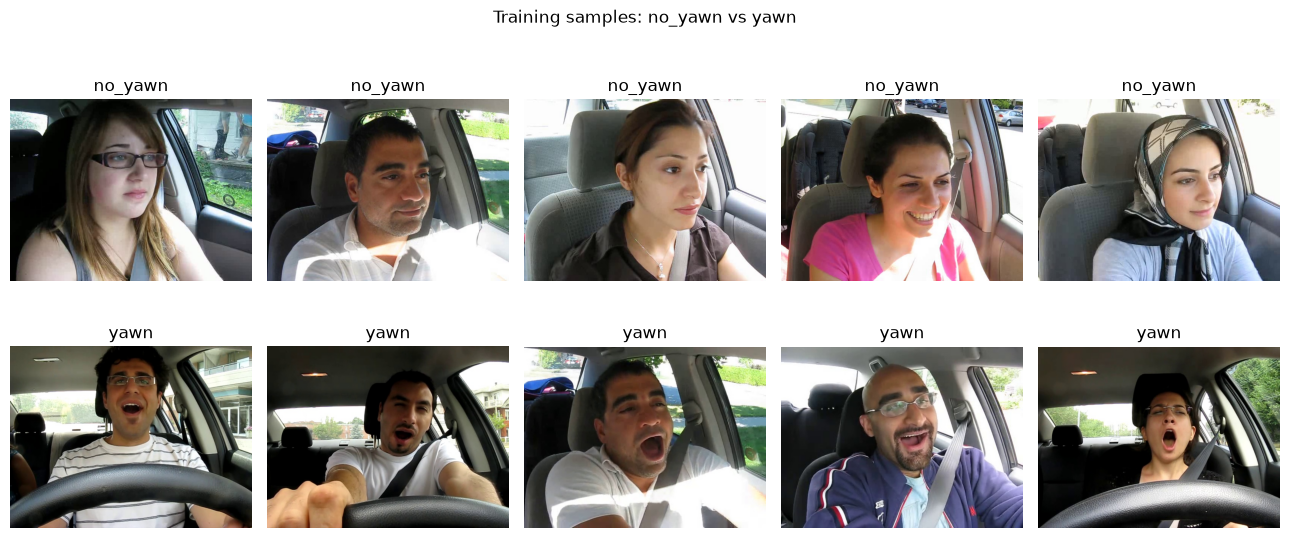

In [5]:
# Cell 5 — Preview sample images
fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for row, class_name in enumerate(["no_yawn", "yawn"]):
    subset = train_mouth[train_mouth["class_name"] == class_name]
    samples = subset.sample(min(5, len(subset)), random_state=SEED)
    for col, (_, sample) in enumerate(samples.iterrows()):
        with Image.open(sample["resolved_path"]) as im:
            axes[row, col].imshow(im.convert("RGB"))
        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")
    for col in range(len(samples), 5):
        axes[row, col].axis("off")
plt.suptitle("Training samples: no_yawn vs yawn")
plt.tight_layout()
plt.show()

In [6]:
# Cell 6 — Build datasets using MobileNetV2 preprocessing
AUTOTUNE = tf.data.AUTOTUNE
preprocess_input = keras.applications.mobilenet_v2.preprocess_input

def decode_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    # preprocess_input expects pixel values in the 0–255 range and scales to [-1, 1].
    image = preprocess_input(image)
    return image, tf.cast(label, tf.float32)

def make_dataset(frame, training=False):
    paths = frame["resolved_path"].astype(str).to_numpy()
    labels = frame["label"].to_numpy().astype(np.float32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_mouth, training=True)
val_ds = make_dataset(val_mouth)
test_ds = make_dataset(test_mouth)

images_batch, labels_batch = next(iter(train_ds))
print("Image batch shape:", images_batch.shape)
print("Preprocessed pixel range:",
      float(tf.reduce_min(images_batch)), "to", float(tf.reduce_max(images_batch)))
print("Label batch shape:", labels_batch.shape)

Image batch shape: (32, 224, 224, 3)
Preprocessed pixel range: -1.0 to 1.0
Label batch shape: (32,)


In [7]:
# Cell 7 — Build MobileNetV2 transfer-learning model
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.04, fill_mode="reflect", seed=SEED),
    layers.RandomZoom(0.08, fill_mode="reflect", seed=SEED)
], name="mouth_data_augmentation")

base_model = keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = keras.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3), name="image")
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dropout(0.3, name="head_dropout_1")(x)
x = layers.Dense(128, activation="relu", name="dense_128")(x)
x = layers.Dropout(0.2, name="head_dropout_2")(x)
outputs = layers.Dense(1, activation="sigmoid", name="yawn_probability")(x)

model = keras.Model(inputs, outputs, name="mobilenetv2_mouth")
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)
model.summary()

Model: "mobilenetv2_mouth"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mouth_data_augmentation         │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout_1 (Dropout)        │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout_2 (Dropout)        │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ yawn_probability (Dense)        │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [8]:
# Cell 8 — Train classification head
HEAD_MODEL_PATH = MODEL_DIR / "mobilenetv2_mouth.keras"
BEST_HEAD_PATH = MODEL_DIR / "mobilenetv2_mouth_best.keras"

head_callbacks = [
    keras.callbacks.ModelCheckpoint(
        str(BEST_HEAD_PATH), monitor="val_loss", save_best_only=True, verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7, verbose=1
    ),
    keras.callbacks.CSVLogger(str(OUTPUT_DIR / "head_training_log.csv"))
]

head_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    callbacks=head_callbacks,
    verbose=1
)

model = keras.models.load_model(BEST_HEAD_PATH)
model.save(HEAD_MODEL_PATH)
print("Saved head model:", HEAD_MODEL_PATH)

Epoch 1/15


d:\driver drowsiness detection\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 521ms/step - accuracy: 0.6308 - auc: 0.6822 - loss: 0.6567 - precision: 0.6369 - recall: 0.6085
Epoch 1: val_loss improved from None to 0.55550, saving model to D:\driver drowsiness detection final\models\mouth_state\mobilenetv2_mouth_best.keras

Epoch 1: finished saving model to D:\driver drowsiness detection final\models\mouth_state\mobilenetv2_mouth_best.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 27s 706ms/step - accuracy: 0.6308 - auc: 0.6822 - loss: 0.6567 - precision: 0.6369 - recall: 0.6085 - val_accuracy: 0.6842 - val_auc: 0.7858 - val_loss: 0.5555 - val_precision: 0.8966 - val_recall: 0.4194 - learning_rate: 0.0010
Epoch 2/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 521ms/step - accuracy: 0.7120 - auc: 0.7928 - loss: 0.5244 - precision: 0.7402 - recall: 0.6531
Epoch 2: val_loss improved from 0.55550 to 0.50815, saving model to D:\driver drowsiness detection final\models\mouth_state\mobilenetv2_mouth_best.keras

Epoch 2: finished saving model to D:\driver drowsiness de

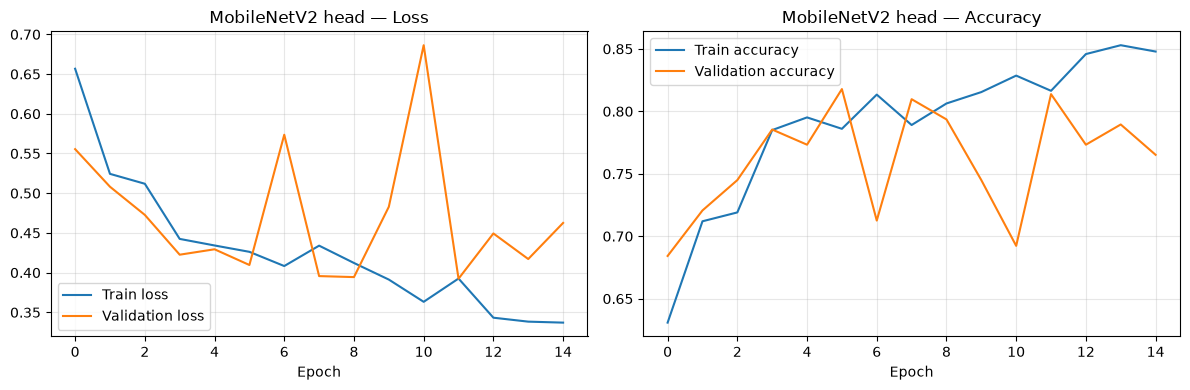

In [9]:
# Cell 9 — Plot classification-head training curves
head_history_df = pd.DataFrame(head_history.history)
head_history_df.to_csv(OUTPUT_DIR / "head_history.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(head_history_df["loss"], label="Train loss")
axes[0].plot(head_history_df["val_loss"], label="Validation loss")
axes[0].set_title("MobileNetV2 head — Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(head_history_df["accuracy"], label="Train accuracy")
axes[1].plot(head_history_df["val_accuracy"], label="Validation accuracy")
axes[1].set_title("MobileNetV2 head — Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "head_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
# Cell 10 — Optional fine-tuning of the last backbone layers
# This improves task-specific adaptation while keeping most pretrained layers frozen.
FINE_TUNED_PATH = MODEL_DIR / "mobilenetv2_mouth_finetuned.keras"
BEST_FINE_TUNED_PATH = MODEL_DIR / "mobilenetv2_mouth_finetuned_best.keras"

base_model = model.get_layer("mobilenetv2_1.00_224")
base_model.trainable = True

# Unfreeze only the last 30 layers; keep BatchNormalization layers frozen.
for layer in base_model.layers[:-30]:
    layer.trainable = False
for layer in base_model.layers[-30:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

print("Trainable backbone layers:", sum(layer.trainable for layer in base_model.layers))
print("Total model parameters:", model.count_params())

fine_callbacks = [
    keras.callbacks.ModelCheckpoint(
        str(BEST_FINE_TUNED_PATH), monitor="val_loss", save_best_only=True, verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7, verbose=1
    ),
    keras.callbacks.CSVLogger(str(OUTPUT_DIR / "fine_tuning_log.csv"))
]

fine_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=fine_callbacks,
    verbose=1
)

# Use the best validation-loss checkpoint from fine-tuning.
if BEST_FINE_TUNED_PATH.exists():
    model = keras.models.load_model(BEST_FINE_TUNED_PATH)
else:
    model = keras.models.load_model(HEAD_MODEL_PATH)

model.save(FINE_TUNED_PATH)
print("Saved selected model:", FINE_TUNED_PATH)

Trainable backbone layers: 19
Total model parameters: 2422081
Epoch 1/10


d:\driver drowsiness detection\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 663ms/step - accuracy: 0.8469 - auc: 0.9213 - loss: 0.3526 - precision: 0.8750 - recall: 0.8093
Epoch 1: val_loss improved from None to 0.39452, saving model to D:\driver drowsiness detection final\models\mouth_state\mobilenetv2_mouth_finetuned_best.keras

Epoch 1: finished saving model to D:\driver drowsiness detection final\models\mouth_state\mobilenetv2_mouth_finetuned_best.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 34s 892ms/step - accuracy: 0.8469 - auc: 0.9213 - loss: 0.3526 - precision: 0.8750 - recall: 0.8093 - val_accuracy: 0.8016 - val_auc: 0.9371 - val_loss: 0.3945 - val_precision: 0.9870 - val_recall: 0.6129 - learning_rate: 1.0000e-05
Epoch 2/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 639ms/step - accuracy: 0.8560 - auc: 0.9376 - loss: 0.3198 - precision: 0.8679 - recall: 0.8398
Epoch 2: val_loss improved from 0.39452 to 0.33313, saving model to D:\driver drowsiness detection final\models\mouth_state\mobilenetv2_mouth_finetuned_best.keras

Epoch 2: finished savin

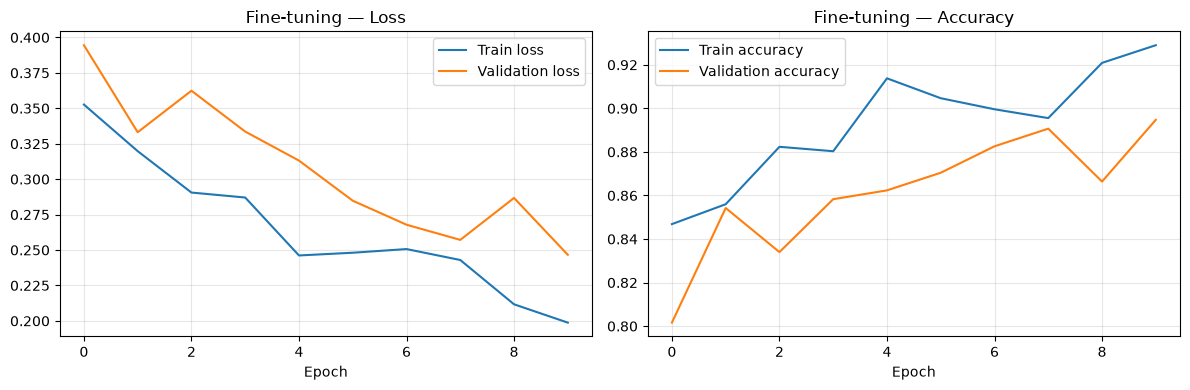

In [11]:
# Cell 11 — Plot fine-tuning curves
fine_history_df = pd.DataFrame(fine_history.history)
fine_history_df.to_csv(OUTPUT_DIR / "fine_tuning_history.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(fine_history_df["loss"], label="Train loss")
axes[0].plot(fine_history_df["val_loss"], label="Validation loss")
axes[0].set_title("Fine-tuning — Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(fine_history_df["accuracy"], label="Train accuracy")
axes[1].plot(fine_history_df["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Fine-tuning — Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fine_tuning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [1]:
# Cell 12 — Threshold comparison for final test evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import pandas as pd
import numpy as np

# Get prediction probabilities
test_probabilities = model.predict(test_ds, verbose=1).ravel()

y_true = test_mouth["label"].to_numpy().astype(int)

# Compare different thresholds
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.50]

comparison_results = []

for threshold in thresholds:

    y_pred = (test_probabilities >= threshold).astype(int)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    comparison_results.append({
        "Threshold": threshold,
        "Accuracy": round(accuracy_score(y_true, y_pred), 4),
        "Precision": round(precision_score(y_true, y_pred, zero_division=0), 4),
        "Recall": round(recall_score(y_true, y_pred, zero_division=0), 4),
        "F1 Score": round(f1_score(y_true, y_pred, zero_division=0), 4),
        "False Positives": int(cm[0, 1]),
        "False Negatives": int(cm[1, 0])
    })

comparison_df = pd.DataFrame(comparison_results)

print("\nTHRESHOLD COMPARISON")
display(comparison_df)

# Display confusion matrix for each threshold
for threshold in thresholds:

    y_pred = (test_probabilities >= threshold).astype(int)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    print(f"\nThreshold: {threshold}")
    print("Rows = Actual | Columns = Predicted")
    print(cm)

NameError: name 'model' is not defined

In [13]:
# Cell 13 — Save test predictions and run configuration
predictions = test_mouth[["path", "class_name", "label"]].copy()
predictions["true_label"] = y_true
predictions["predicted_label"] = y_pred
predictions["predicted_class"] = np.where(y_pred == 1, "yawn", "no_yawn")
predictions["yawn_probability"] = test_probabilities
predictions["correct"] = predictions["true_label"] == predictions["predicted_label"]
predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

errors = predictions[~predictions["correct"]].copy()
errors.to_csv(OUTPUT_DIR / "misclassified_test_images.csv", index=False)

config = {
    "model_name": "MobileNetV2 Mouth-State Classifier",
    "classes": CLASS_TO_INDEX,
    "image_size": list(IMG_SIZE),
    "batch_size": BATCH_SIZE,
    "head_max_epochs": HEAD_EPOCHS,
    "fine_tune_max_epochs": FINE_TUNE_EPOCHS,
    "seed": SEED,
    "selected_model_path": str(FINE_TUNED_PATH),
    "train_samples": int(len(train_mouth)),
    "validation_samples": int(len(val_mouth)),
    "test_samples": int(len(test_mouth)),
    "metrics": metrics
}
with open(OUTPUT_DIR / "run_configuration.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

print("Correct predictions:", int(predictions["correct"].sum()), "/", len(predictions))
print("Incorrect predictions:", int((~predictions["correct"]).sum()))
print("Artifacts saved to:", OUTPUT_DIR)
display(predictions.head(10))
print("Notebook 06 completed. Next: Notebook 07 — Model Evaluation and Comparison.")

Correct predictions: 187 / 215
Incorrect predictions: 28
Artifacts saved to: D:\driver drowsiness detection final\outputs\training\mobilenetv2_mouth


,path,class_name,label,true_label,predicted_label,predicted_class,yawn_probability,correct
0,D:\driver drowsiness detection final\data\raw\...,no_yawn,0,0,0,no_yawn,0.081549,True
1,D:\driver drowsiness detection final\data\raw\...,no_yawn,0,0,0,no_yawn,0.140258,True
2,D:\driver drowsiness detection final\data\raw\...,no_yawn,0,0,0,no_yawn,0.012570,True
3,D:\driver drowsiness detection final\data\raw\...,no_yawn,0,0,0,no_yawn,0.012296,True
4,D:\driver drowsiness detection final\data\raw\...,no_yawn,0,0,0,no_yawn,0.063567,True
5,D:\driver drowsiness detection final\data\raw\...,no_yawn,0,0,0,no_yawn,0.146998,True
6,D:\driver drowsiness detection final\data\raw\...,no_yawn,0,0,0,no_yawn,0.064120,True
7,D:\driver drowsiness detection final\data\raw\...,no_yawn,0,0,0,no_yawn,0.049175,True
8,D:\driver drowsiness detection final\data\raw\...,no_yawn,0,0,0,no_yawn,0.350391,True
9,D:\driver drowsiness detection final\data\raw\...,no_yawn,0,0,0,no_yawn,0.047625,True


Notebook 06 completed. Next: Notebook 07 — Model Evaluation and Comparison.
